In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"
if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
else:
    os.system(f"cd {REPO_DIR} && git pull")
sys.path.append(REPO_DIR)

from utils import make_log_row, validate_log

def find_one(name, roots):
    """Return the path of exactly one file called `name`. Refuses to guess when
    two copies exist (e.g. an old and a new Step 5 output attached together)."""
    for root in roots:
        matches = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if len(matches) == 1:
            return matches[0]
        if len(matches) > 1:
            raise RuntimeError(f"{name}: {len(matches)} copies under {root}. Attach only one:\n" + "\n".join(matches))
    raise FileNotFoundError(f"{name} not found under {roots}")

INPUT_ROOT = "/kaggle/input"
STEP5_FILES = ["quality_filtered_faces.csv", "step5_video_stats.csv", "step5_failed_videos.csv",
               "step5_overall_summary.csv"]
paths = {n: find_one(n, [INPUT_ROOT]) for n in STEP5_FILES}
paths["video_split_map.csv"] = find_one("video_split_map.csv", [REPO_DIR, INPUT_ROOT])
for k, v in paths.items():
    print(f"{k:32s} {v}")

Cloning into '/kaggle/working/repo'...


quality_filtered_faces.csv       /kaggle/input/datasets/mugdhanaik/step5-quality-filtered-csvs/quality_filtered_faces.csv
step5_video_stats.csv            /kaggle/input/datasets/mugdhanaik/step5-video-stats/step5_video_stats.csv
step5_failed_videos.csv          /kaggle/input/datasets/mugdhanaik/step5-failed-videos/step5_failed_videos.csv
step5_overall_summary.csv        /kaggle/input/datasets/mugdhanaik/step5-overall-summary/step5_overall_summary.csv
video_split_map.csv              /kaggle/input/datasets/mugdhanaik/video-split/video_split_map.csv


In [2]:
# ============================================================
# STEPS 1-3 come from logs/cleaning_log.csv (written by clean_videos.py).
# If that file is not committed, fill MANUAL_STEPS_1_3 from your local run:
#   {"1_video_integrity": (input, removed), "2_duplicate_detection": (input, removed),
#    "3_label_consistency": (input, removed)}
# ============================================================
MANUAL_STEPS_1_3 = None

try:
    log123_path = find_one("cleaning_log.csv", [REPO_DIR])
    log123 = pd.read_csv(log123_path)
    print("Steps 1-3 log:", log123_path)
except FileNotFoundError:
    assert MANUAL_STEPS_1_3, "logs/cleaning_log.csv not found: commit it, or fill MANUAL_STEPS_1_3 above"
    reasons = {"1_video_integrity": "failed to open / unreadable",
               "2_duplicate_detection": "identical file hash (MD5)",
               "3_label_consistency": "folder name did not match expected labels"}
    log123 = pd.DataFrame([{"step": k, "input_count": a, "removed_count": r, "output_count": a - r,
                            "reason": reasons[k]} for k, (a, r) in MANUAL_STEPS_1_3.items()])
    print("Steps 1-3: using MANUAL_STEPS_1_3")
log123

Steps 1-3 log: /kaggle/working/repo/logs/cleaning_log.csv


,step,input_count,removed_count,output_count,reason
0,1_video_integrity,13529,0,13529,failed to open / unreadable
1,2_duplicate_detection,13529,0,13529,identical file hash (MD5)
2,3_label_consistency,13529,0,13529,folder name did not match expected labels


In [3]:
# ============================================================
# LOAD STEP 5 / 6b OUTPUTS
# ============================================================
smap    = pd.read_csv(paths["video_split_map.csv"])
faces   = pd.read_csv(paths["quality_filtered_faces.csv"])
stats   = pd.read_csv(paths["step5_video_stats.csv"])
failed  = pd.read_csv(paths["step5_failed_videos.csv"])
overall = pd.read_csv(paths["step5_overall_summary.csv"]).iloc[0]

n_failed = len(failed)
print("split map videos:", len(smap), "| sampled & processed:", len(stats), "| failed:", n_failed,
      "| final faces:", len(faces))
assert {"dataset", "split"} <= set(faces.columns), "Step 5 output has no dataset/split columns: use the scaled Step 5"

split map videos: 13529 | sampled & processed: 960 | failed: 0 | final faces: 28184


In [4]:
# ============================================================
# BUILD THE LOG (one row per stage)
# ============================================================
rows = []

# ---- Steps 1-3 (video level) ----
for _, r in log123.iterrows():
    rows.append(make_log_row(step=r["step"], level="video", unit="videos",
                             n_in=int(r["input_count"]), n_out=int(r["output_count"]),
                             action="removed", reason=r["reason"], source="logs/cleaning_log.csv"))

n_clean = int(log123.iloc[-1]["output_count"])
assert n_clean == len(smap), f"clean list ({n_clean}) != split map ({len(smap)}): different video lists"

# ---- Step 6: official splits (video level) ----
n_excl = int((smap["split"] == "excluded").sum())
n_unused = int((smap["split"] == "unused").sum())
n_usable = int(smap["split"].isin(["train", "val", "test"]).sum())
rows.append(make_log_row("6_split_excluded", "video", "videos", len(smap), len(smap) - n_excl, "removed",
            "no official split (DeepFakeDetection is not covered by the FF++ split files)", "video_split_map.csv"))
rows.append(make_log_row("6_split_unused", "video", "videos", len(smap) - n_excl, n_usable, "removed",
            "Celeb-DF videos outside the official test list are not used (Celeb-DF is test-only)", "video_split_map.csv"))

# ---- Step 5 sampling + extraction failures (video level) ----
n_sampled = len(stats) + n_failed
rows.append(make_log_row("5_sampling", "video", "videos", n_usable, n_sampled, "removed",
            "stratified sample (dataset x label x split) chosen for compute; fixed seed", "step5_video_stats.csv"))
rows.append(make_log_row("4_extraction_failures", "video", "videos", n_sampled, len(stats), "removed",
            "video raised an error during extraction (see step5_failed_videos.csv)", "step5_failed_videos.csv"))
n_with_face = int((stats["faces_detected"] > 0).sum())
rows.append(make_log_row("4_videos_without_face", "video", "videos", len(stats), n_with_face, "removed",
            "no face detected in any sampled frame", "step5_video_stats.csv"))

# ---- Step 4 face detection (frame level) ----
est = stats["frames_sampled_est"].astype(int)
det = stats["faces_detected"].astype(int)
over = int((det > est).sum())
if over:
    print(f"NOTE: frames_sampled_est is below faces_detected for {over} videos (frame counts are approximate); clipped.")
rows.append(make_log_row("4_face_detection", "frame", "frames", int(est.sum()), int(np.minimum(det, est).sum()), "removed",
            "no face detected, or confidence below threshold (frames sampled is estimated from each video's frame count)",
            "step5_video_stats.csv"))

# ---- faces-per-video cap (face level) ----
cap = int(overall["max_faces_per_video"])
rows.append(make_log_row("4_faces_per_video_cap", "face", "faces", int(det.sum()), int(stats["faces_kept"].sum()), "removed",
            f"cap of {cap} faces per video, evenly spaced, so long videos do not dominate", "step5_video_stats.csv"))

# ---- Step 5 quality (face level) ----
tot_in, remaining = int(overall["total_faces_in"]), int(overall["remaining"])
assert tot_in == int(stats["faces_kept"].sum()), "Step 5 faces-in != sum of faces_kept"
rows.append(make_log_row("5_size_filter", "face", "faces", tot_in, remaining, "removed",
            "face crop smaller than the minimum size", "step5_overall_summary.csv"))
n_vid_final = int(faces["video_id"].nunique())
rows.append(make_log_row("5_videos_lost_to_size_filter", "video", "videos", n_with_face, n_vid_final, "removed",
            "every face of the video was below the minimum crop size, so the video left the dataset", "quality_filtered_faces.csv"))
flagged = int((~faces["blur_pass"].astype(bool)).sum())      # flagged faces in the FINAL dataset (after the size filter)
rows.append(make_log_row("5_blur_flag", "face", "faces", remaining, remaining, "flagged",
            f"{flagged} faces flagged low-blur and KEPT (blur is not a filter; it is a dataset/compression signal)",
            "step5_overall_summary.csv"))

# ---- Step 7 final ----
assert remaining == len(faces), f"final faces ({len(faces)}) != remaining after size filter ({remaining})"
rows.append(make_log_row("7_final_dataset", "face", "faces", remaining, len(faces), "info",
            "final face dataset; class balance documented in Step 7, not forced", "quality_filtered_faces.csv"))

log = pd.DataFrame(rows)
validate_log(log)
pd.set_option("display.width", 220, "display.max_colwidth", 70)
log[["step", "level", "n_in", "n_removed", "n_out", "pct_removed", "action"]]

,step,level,n_in,n_removed,n_out,pct_removed,action
0,1_video_integrity,video,13529,0,13529,0.00,removed
1,2_duplicate_detection,video,13529,0,13529,0.00,removed
2,3_label_consistency,video,13529,0,13529,0.00,removed
3,6_split_excluded,video,13529,1000,12529,7.39,removed
4,6_split_unused,video,12529,6011,6518,47.98,removed
5,5_sampling,video,6518,5558,960,85.27,removed
6,4_extraction_failures,video,960,0,960,0.00,removed
7,4_videos_without_face,video,960,0,960,0.00,removed
8,4_face_detection,frame,43720,0,43720,0.00,removed
9,4_faces_per_video_cap,face,43720,15097,28623,34.53,removed


In [5]:
# ============================================================
# FINAL COUNTS per dataset x label x split  (what training will actually see)
# ============================================================
final_counts = (faces.groupby(["dataset", "label_name", "split"])
                     .agg(videos=("video_id", "nunique"), faces=("face_path", "size"))
                     .reset_index())
final_counts

,dataset,label_name,split,videos,faces
0,Celeb-DF,FAKE,test,150,4382
1,Celeb-DF,REAL,test,150,4381
2,FaceForensics++,FAKE,test,100,3000
3,FaceForensics++,FAKE,train,195,5850
4,FaceForensics++,FAKE,val,30,897
5,FaceForensics++,REAL,test,98,2883
6,FaceForensics++,REAL,train,198,5891
7,FaceForensics++,REAL,val,30,900


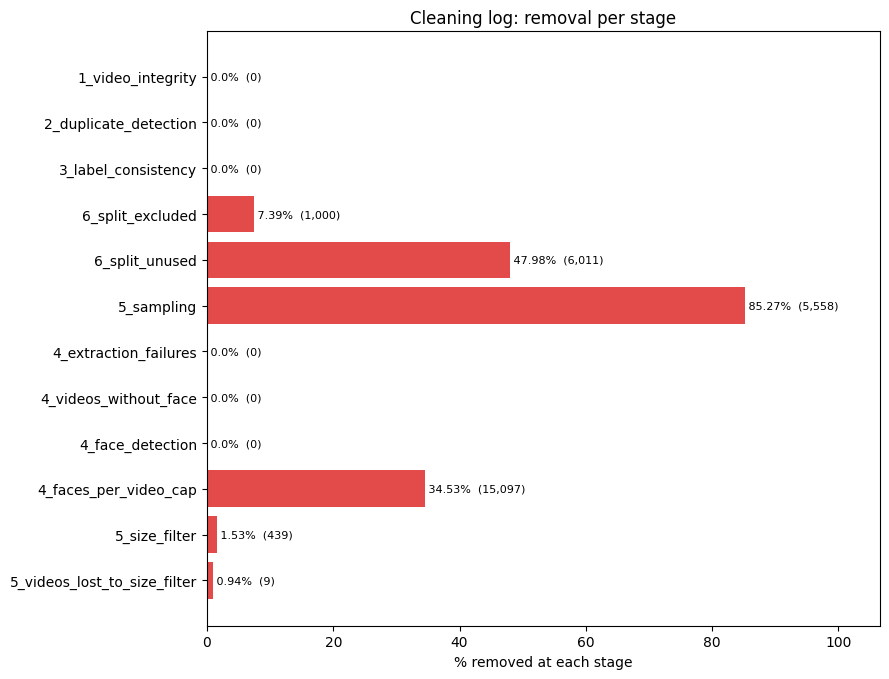

STEP 8 - CONSOLIDATED CLEANING LOG

1_video_integrity: 13,529 videos in, 0 removed (0.0%). failed to open / unreadable.
2_duplicate_detection: 13,529 videos in, 0 removed (0.0%). identical file hash (MD5).
3_label_consistency: 13,529 videos in, 0 removed (0.0%). folder name did not match expected labels.
6_split_excluded: 13,529 videos in, 1,000 removed (7.39%). no official split (DeepFakeDetection is not covered by the FF++ split files).
6_split_unused: 12,529 videos in, 6,011 removed (47.98%). Celeb-DF videos outside the official test list are not used (Celeb-DF is test-only).
5_sampling: 6,518 videos in, 5,558 removed (85.27%). stratified sample (dataset x label x split) chosen for compute; fixed seed.
4_extraction_failures: 960 videos in, 0 removed (0.0%). video raised an error during extraction (see step5_failed_videos.csv).
4_videos_without_face: 960 videos in, 0 removed (0.0%). no face detected in any sampled frame.
4_face_detection: 43,720 frames in, 0 removed (0.0%). no face d

In [6]:
# ============================================================
# SAVE: table, plain-English summary, drop-off chart
# ============================================================
OUT = "/kaggle/working/step8_cleaning_log"
os.makedirs(OUT, exist_ok=True)

log.to_csv(os.path.join(OUT, "cleaning_log_full.csv"), index=False)
final_counts.to_csv(os.path.join(OUT, "final_counts.csv"), index=False)

lines = ["STEP 8 - CONSOLIDATED CLEANING LOG", "=" * 60, ""]
for _, r in log.iterrows():
    if r["action"] == "removed":
        lines.append(f"{r['step']}: {r['n_in']:,} {r['unit']} in, {r['n_removed']:,} removed ({r['pct_removed']}%). {r['reason']}.")
    else:
        lines.append(f"{r['step']}: {r['n_in']:,} {r['unit']} ({r['action']}). {r['reason']}.")
lines += ["", "Final dataset (faces / videos per dataset x label x split):", final_counts.to_string(index=False), "",
          "Note: Steps 1-3 ran on every video in the dataset. Steps 4-5 ran on a stratified sample chosen for compute; "
          "the sampling row above records how many videos were not sampled."]
with open(os.path.join(OUT, "cleaning_summary.txt"), "w") as f:
    f.write("\n".join(lines) + "\n")

rem = log[(log["action"] == "removed") & (log["n_in"] > 0)]
fig, ax = plt.subplots(figsize=(9, 0.45 * len(rem) + 1.5))
ax.barh(rem["step"][::-1], rem["pct_removed"][::-1], color="#E24B4A")
for y, (p, n) in enumerate(zip(rem["pct_removed"][::-1], rem["n_removed"][::-1])):
    ax.text(p, y, f" {p}%  ({n:,})", va="center", fontsize=8)
ax.set_xlabel("% removed at each stage"); ax.set_title("Cleaning log: removal per stage")
ax.set_xlim(0, max(rem["pct_removed"].max() * 1.25, 1))
plt.tight_layout(); plt.savefig(os.path.join(OUT, "cleaning_dropoff_chart.png"), dpi=150); plt.show()

print("\n".join(lines))
print("\nSaved to", OUT)

In [7]:
d = stats["frames_sampled_est"] - stats["faces_detected"]
print(d.describe())
print("videos where faces < sampled frames:", int((d > 0).sum()), "of", len(stats))
print("videos where faces > sampled frames:", int((d < 0).sum()))
print(stats.groupby("dataset").apply(lambda g: (g["frames_sampled_est"] - g["faces_detected"]).mean()).round(2))

count    960.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
dtype: float64
videos where faces < sampled frames: 0 of 960
videos where faces > sampled frames: 0
dataset
Celeb-DF           0.0
FaceForensics++    0.0
dtype: float64


/tmp/ipykernel_16/557040544.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(stats.groupby("dataset").apply(lambda g: (g["frames_sampled_est"] - g["faces_detected"]).mean()).round(2))


In [8]:
import inspect, utils
print(inspect.getsource(utils.extract_faces_from_video))
print(faces["confidence"].describe())
print((faces["confidence"] < 0.90).sum(), "faces below 0.90 confidence")

def extract_faces_from_video(video_path, label_name, faces_dir, video_id,
                              mtcnn, sampling="interval",
                              frame_interval=FRAME_INTERVAL,
                              max_frames=MAX_FRAMES_PER_VIDEO,
                              min_confidence=MIN_CONFIDENCE):
    """
    Run face detection on one video, save the largest confident face per
    sampled frame, and return a list of metadata dicts (one per saved face).
    """
    records = []
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Could not open:", video_path)
        return records

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if sampling == "evenly_spaced":
        if total_frames <= 0:
            cap.release()
            return records
        frame_indices = np.linspace(0, total_frames - 1, min(max_frames, total_frames), dtype=int)
    elif sampling == "interval":
        frame_indices = range(0, total_frames, frame_i